In [2]:
%pip install --quiet torch torchvision pillow numpy scikit-learn matplotlib pykan pyyaml tqdm

Note: you may need to restart the kernel to use updated packages.


Valid subjects: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
[subj 1] ConvAE_Small: AUROC=0.7470319634703196, TPR=1.000, TNR=0.078
[subj 1] ConvAE_Large: AUROC=0.7442922374429223, TPR=1.000, TNR=0.078
[subj 1] FCAE: AUROC=0.7534246575342466, TPR=1.000, TNR=0.078
[subj 2] ConvAE_Small: AUROC=0.4072727272727273, TPR=1.000, TNR=0.023
[subj 2] ConvAE_Large: AUROC=0.40454545454545454, TPR=1.000, TNR=0.023
[subj 2] FCAE: AUROC=0.4136363636363636, TPR=1.000, TNR=0.023
[subj 3] ConvAE_Small: AUROC=0.5642201834862386, TPR=1.000, TNR=0.000
[subj 3] ConvAE_Large: AUROC=0.35229357798165134, TPR=1.000, TNR=0.009
[subj 3] FCAE: AUROC=0.35963302752293574, TPR=1.000, TNR=0.014
[subj 4] ConvAE_Small: AUROC=0.6254545454545455, TPR=1.000, TNR=0.068
[subj 4] ConvAE_Large: AUROC=0.4954545454545455, TPR=1.000, TNR=0.023
[subj 4] FCAE: AUROC=0.4745454545454545, TPR=1.000, TNR=0.018
[subj 5] ConvAE_Small: AUROC=0.6988888888888889, TPR=1.000, TNR=0.027
[subj 5] ConvAE_Large: AUROC=0.8688888888888888, TPR=1.000, TNR=0.058
[s

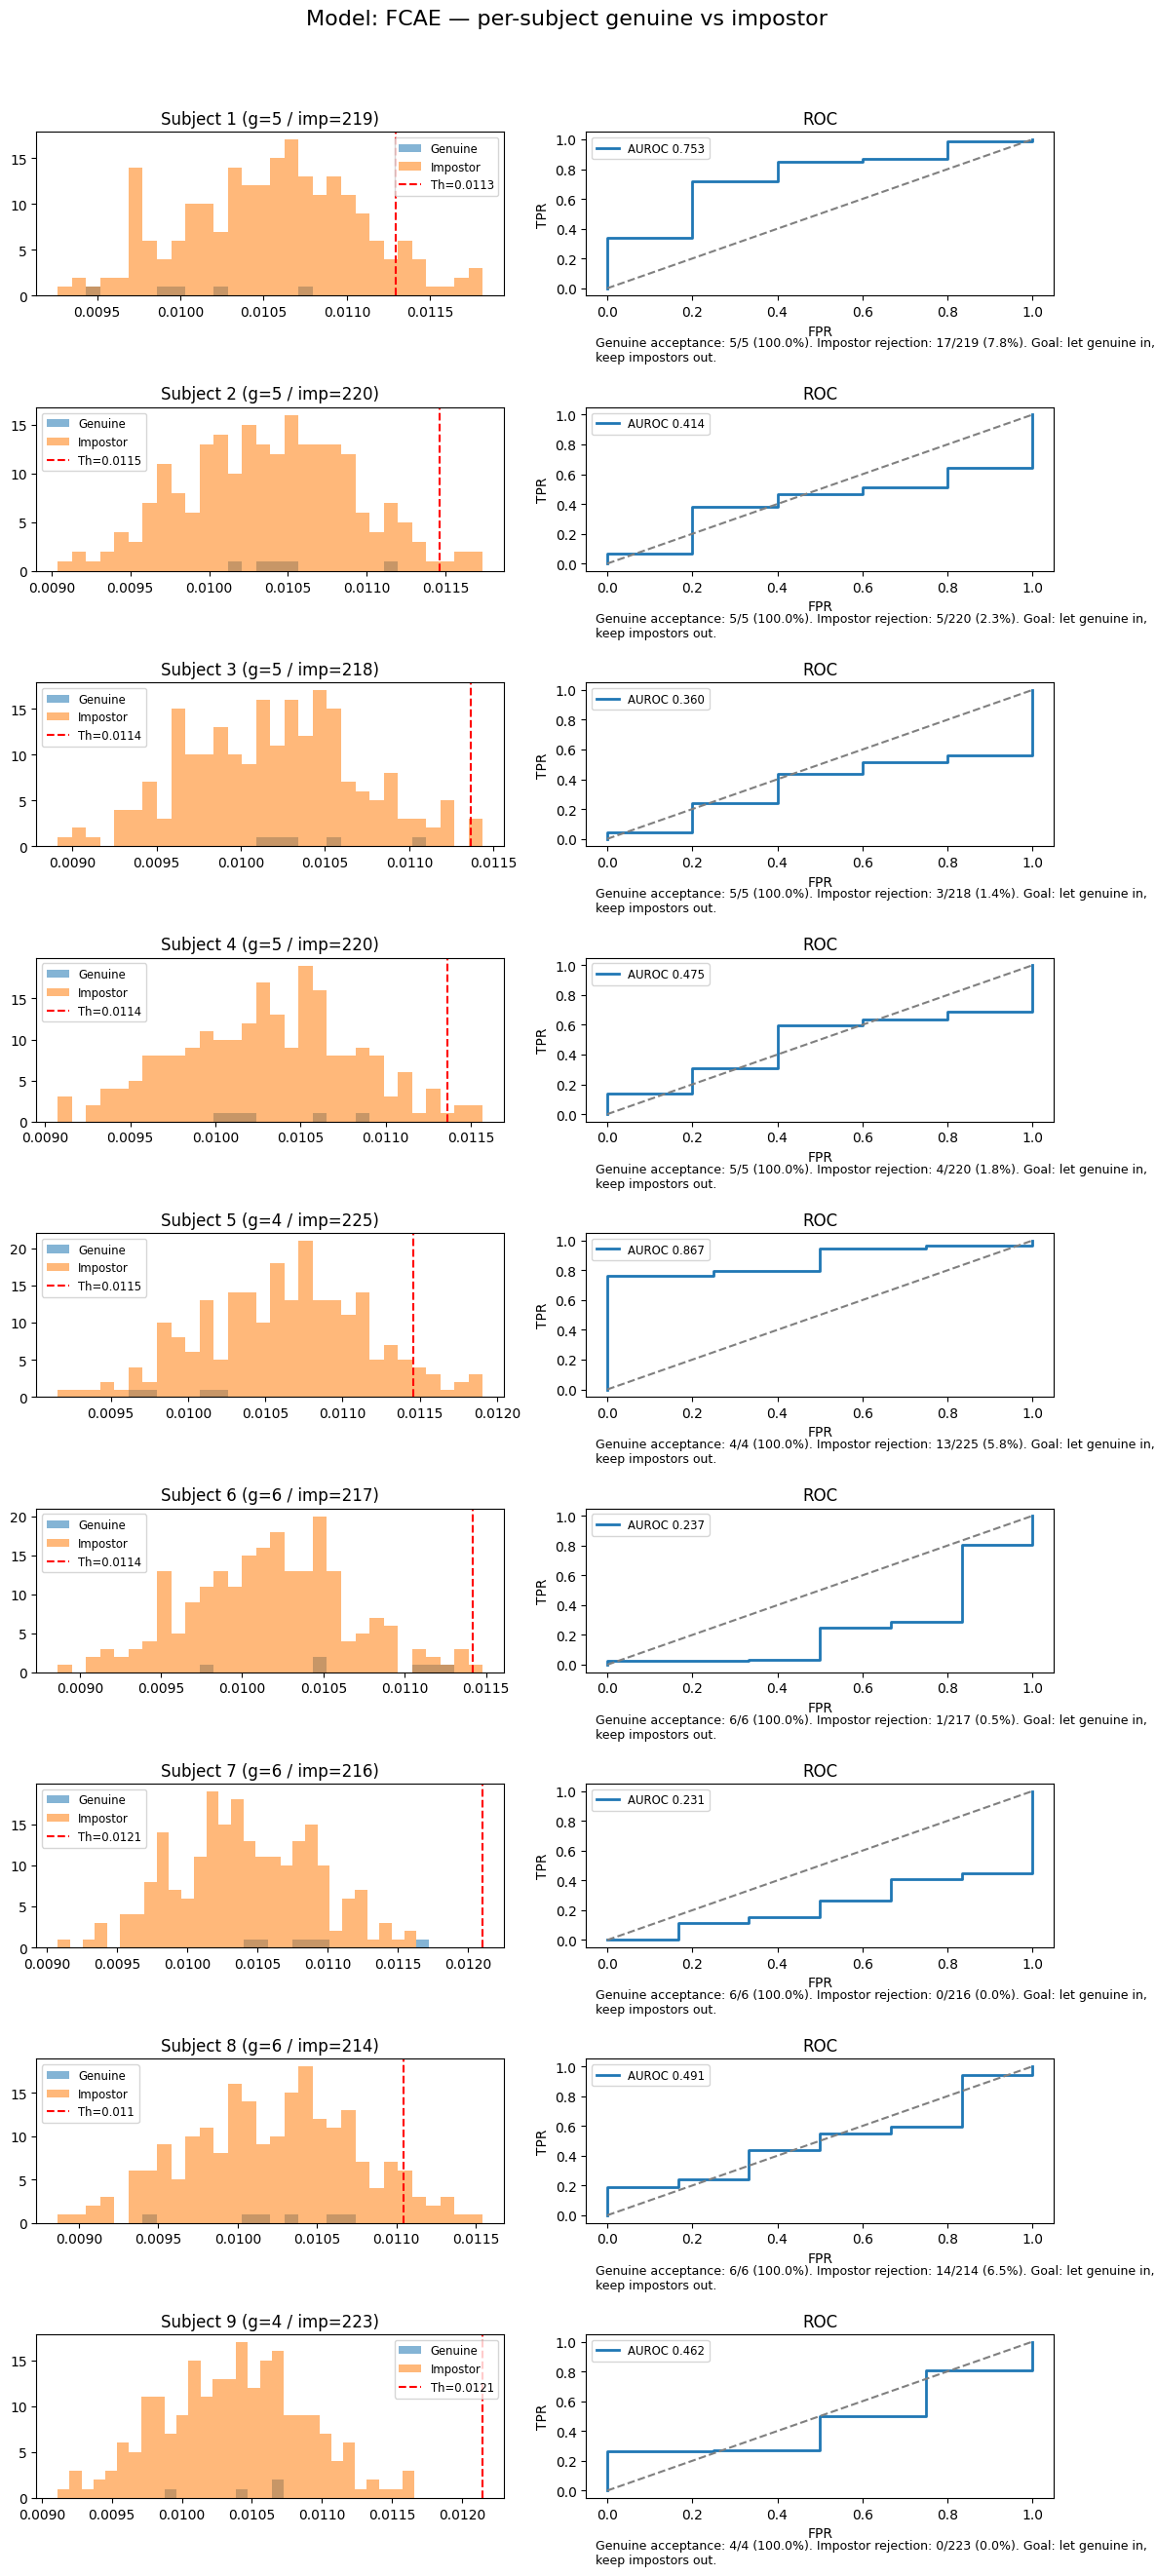

Saved per-model grid to: ./oneclass_results/FCAE_per_subject_grid.png


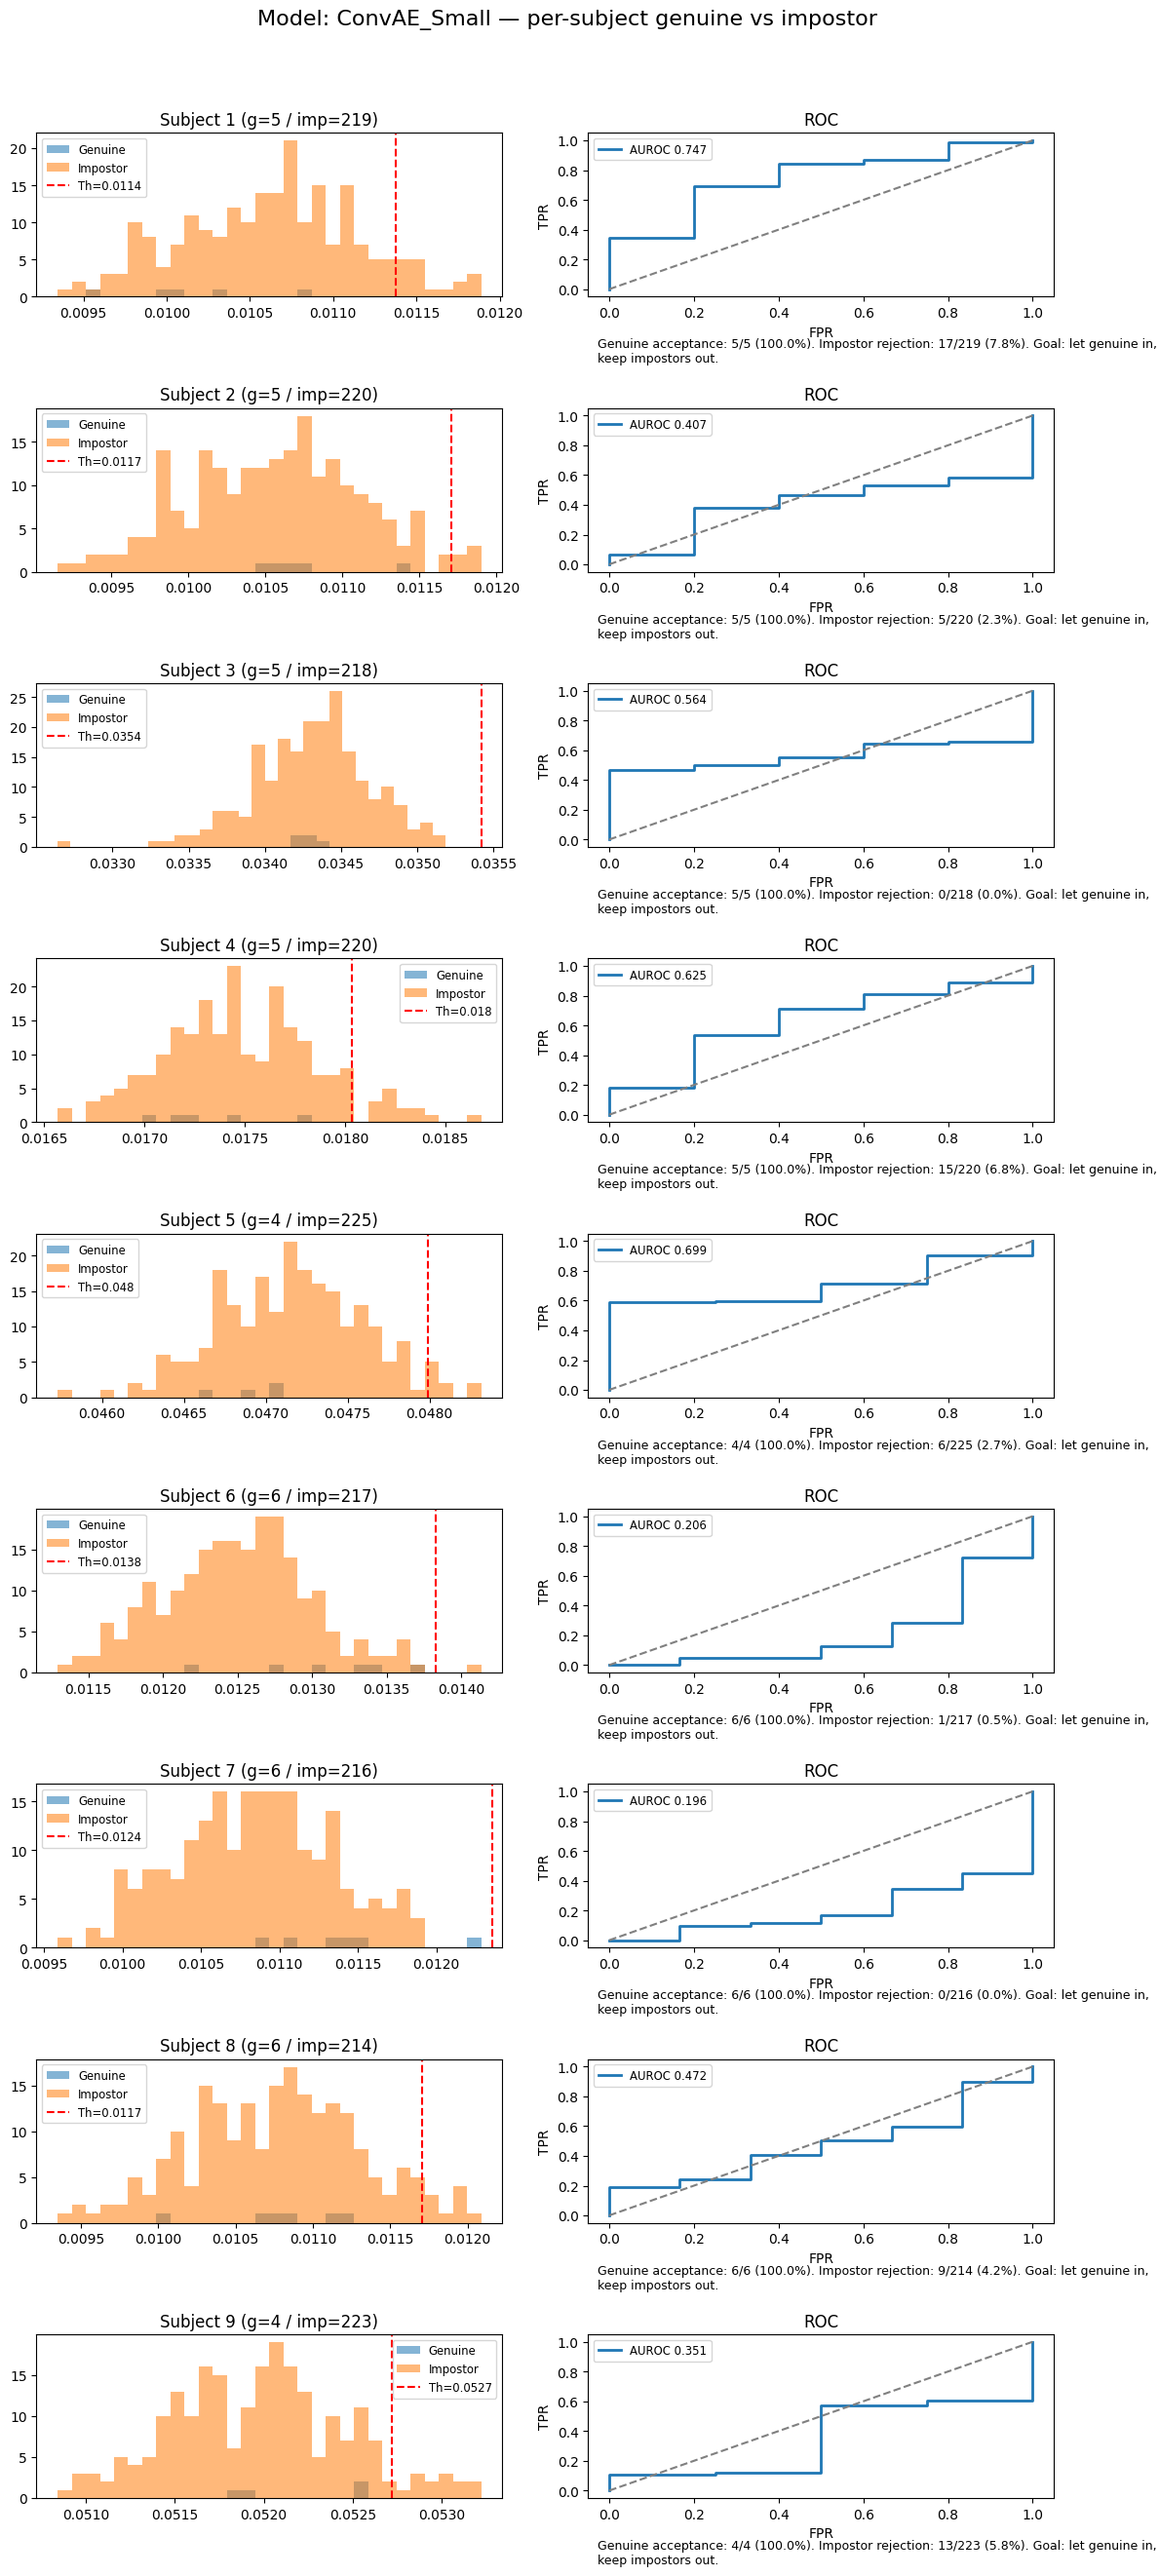

Saved per-model grid to: ./oneclass_results/ConvAE_Small_per_subject_grid.png


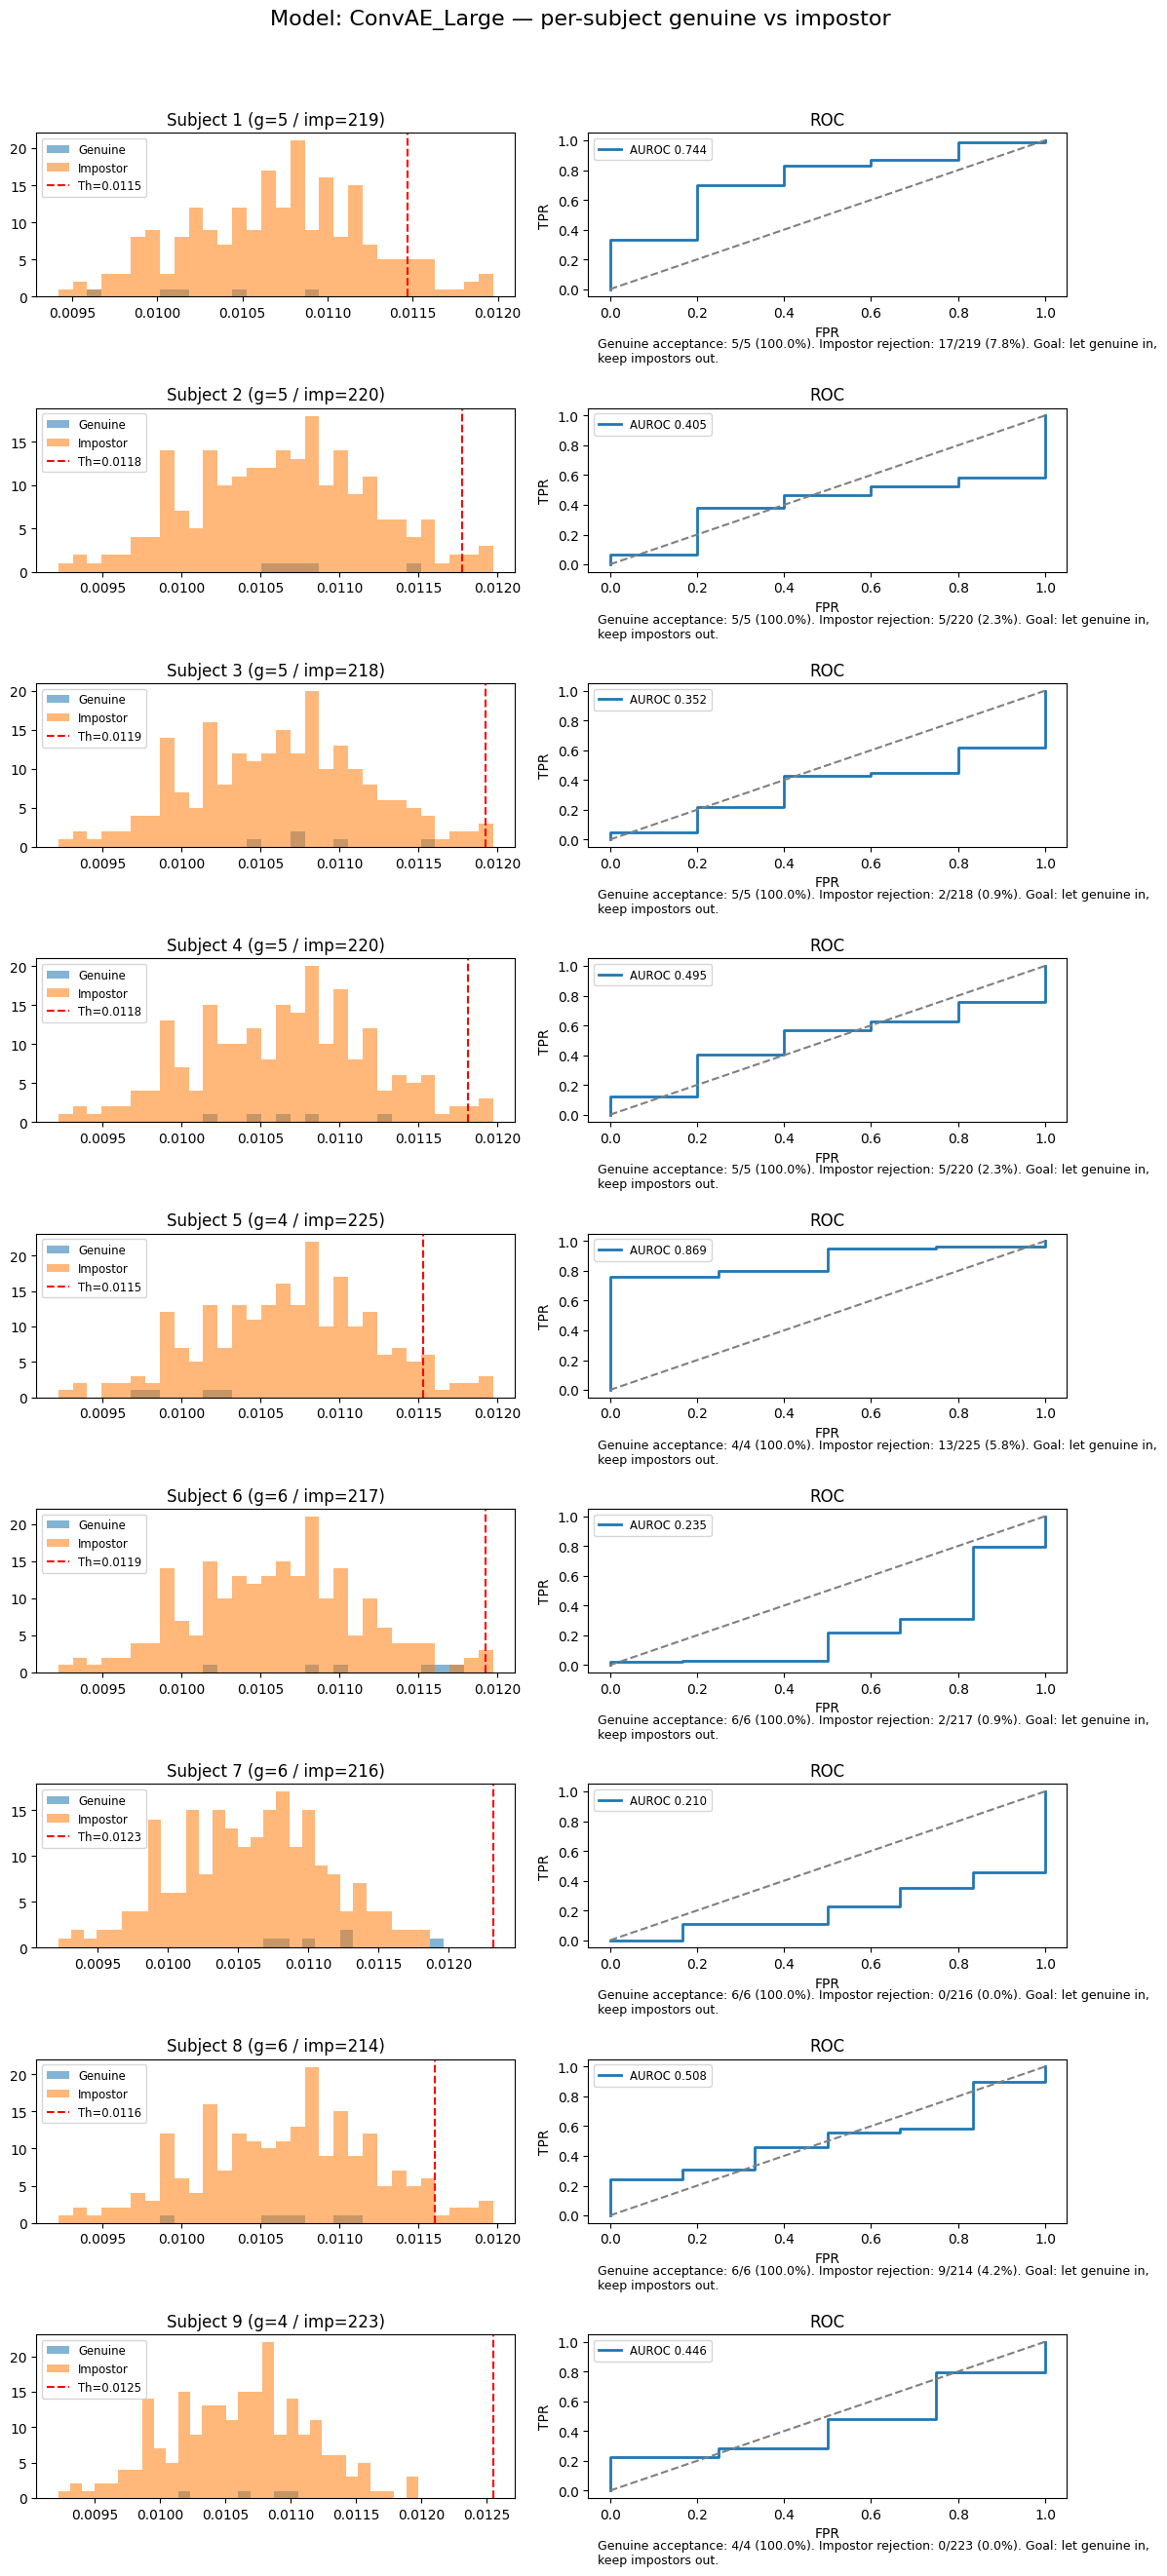

Saved per-model grid to: ./oneclass_results/ConvAE_Large_per_subject_grid.png

SUMMARY (plain language):
- FCAE: On average across subjects, the model correctly ACCEPTS 100.0% of genuine samples and correctly REJECTS 8.5% of impostors. Mean AUROC: 0.511.
- ConvAE_Small: On average across subjects, the model correctly ACCEPTS 100.0% of genuine samples and correctly REJECTS 8.8% of impostors. Mean AUROC: 0.508.
- ConvAE_Large: On average across subjects, the model correctly ACCEPTS 100.0% of genuine samples and correctly REJECTS 6.8% of impostors. Mean AUROC: 0.508.
Saved plain summary to: ./oneclass_results/plain_summary.txt

Done. Check ./oneclass_results for CSV, per-model PNG figures and plain summary.


In [7]:
import os, sys, random, math
import numpy as np
import pandas as pd
import torch
from torch import nn, optim
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from PIL import Image
from sklearn.metrics import roc_curve, auc, precision_recall_curve
import matplotlib.pyplot as plt

# -----------------------
# USER SETTINGS
# -----------------------
IMAGE_DIR = './ecg_wtmm_images'   # expects subject_01 .. subject_N directories
NUM_SUBJECTS = 10                 # nominal number of subject directories to inspect
IMAGE_SIZE = 32                   # resize images to this
BATCH_SIZE = 8
EPOCHS_AE = 12
EPOCHS_FE = 6
LR = 1e-3
MIN_IMAGES_PER_SUBJECT = 8        # subjects with fewer images are skipped
STRICT_THRESHOLD = False          # if True uses max(train_scores), else mean+3*std
DISPLAY_SUBJECTS = 9              # max number of subjects to show per model grid
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SEED = 123

OUT_DIR = './oneclass_results'
os.makedirs(OUT_DIR, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# -----------------------
# Transforms & dataset
# -----------------------
transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor()
])

class ImageDataset(Dataset):
    def __init__(self, image_paths, transform=None):
        self.image_paths = list(image_paths)
        self.transform = transform
    def __len__(self):
        return len(self.image_paths)
    def __getitem__(self, idx):
        p = self.image_paths[idx]
        try:
            img = Image.open(p).convert('L')
        except Exception:
            # fallback black image
            img = Image.fromarray(np.zeros((IMAGE_SIZE, IMAGE_SIZE), dtype=np.uint8)).convert('L')
        x = self.transform(img) if self.transform else transforms.ToTensor()(img)
        return x

# -----------------------
# Autoencoder models (3 variants)
# -----------------------
class ConvAE_Small(nn.Module):
    def __init__(self, img_size=IMAGE_SIZE, latent_dim=128):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, 3, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(16, 32, 3, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(32, 64, 3, stride=2, padding=1), nn.ReLU(),
            nn.Flatten()
        )
        enc_dim = 64 * (img_size // 8) * (img_size // 8)
        self.fc_enc = nn.Linear(enc_dim, latent_dim)
        self.fc_dec = nn.Linear(latent_dim, enc_dim)
        self.decoder = nn.Sequential(
            nn.Unflatten(1, (64, img_size // 8, img_size // 8)),
            nn.ConvTranspose2d(64, 32, 3, stride=2, padding=1, output_padding=1), nn.ReLU(),
            nn.ConvTranspose2d(32, 16, 3, stride=2, padding=1, output_padding=1), nn.ReLU(),
            nn.ConvTranspose2d(16, 1, 3, stride=2, padding=1, output_padding=1), nn.Sigmoid()
        )
    def forward(self, x):
        z = self.encoder(x)
        z = self.fc_enc(z)
        z = self.fc_dec(z)
        out = self.decoder(z)
        return out
    def encode(self, x):
        with torch.no_grad():
            z = self.encoder(x)
            z = self.fc_enc(z)
        return z

class ConvAE_Large(nn.Module):
    def __init__(self, img_size=IMAGE_SIZE, latent_dim=256):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, 3, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(32, 64, 3, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(64, 128, 3, stride=2, padding=1), nn.ReLU(),
            nn.Flatten()
        )
        enc_dim = 128 * (img_size // 8) * (img_size // 8)
        self.fc_enc = nn.Linear(enc_dim, latent_dim)
        self.fc_dec = nn.Linear(latent_dim, enc_dim)
        self.decoder = nn.Sequential(
            nn.Unflatten(1, (128, img_size // 8, img_size // 8)),
            nn.ConvTranspose2d(128, 64, 3, stride=2, padding=1, output_padding=1), nn.ReLU(),
            nn.ConvTranspose2d(64, 32, 3, stride=2, padding=1, output_padding=1), nn.ReLU(),
            nn.ConvTranspose2d(32, 1, 3, stride=2, padding=1, output_padding=1), nn.Sigmoid()
        )
    def forward(self, x):
        z = self.encoder(x)
        z = self.fc_enc(z)
        z = self.fc_dec(z)
        out = self.decoder(z)
        return out
    def encode(self, x):
        with torch.no_grad():
            z = self.encoder(x)
            z = self.fc_enc(z)
        return z

class FCAE(nn.Module):
    def __init__(self, img_size=IMAGE_SIZE, latent_dim=128):
        super().__init__()
        input_dim = img_size * img_size
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(input_dim, 512), nn.ReLU(),
            nn.Linear(512, latent_dim), nn.ReLU()
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 512), nn.ReLU(),
            nn.Linear(512, input_dim), nn.Sigmoid(),
            nn.Unflatten(1, (1, img_size, img_size))
        )
    def forward(self, x):
        z = self.encoder(x)
        out = self.decoder(z)
        return out
    def encode(self, x):
        with torch.no_grad():
            z = self.encoder(x)
        return z

# -----------------------
# Training & scoring helpers
# -----------------------
def train_ae(model, dataloader, device=DEVICE, epochs=EPOCHS_AE, lr=LR, verbose=False):
    model = model.to(device)
    opt = optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    model.train()
    for epoch in range(epochs):
        total = 0.0
        n = 0
        for batch in dataloader:
            batch = batch.to(device)
            out = model(batch)
            loss = loss_fn(out, batch)
            opt.zero_grad(); loss.backward(); opt.step()
            total += float(loss.item()) * batch.size(0)
            n += batch.size(0)
        if verbose:
            print(f"    Epoch {epoch+1}/{epochs} loss={(total / max(1,n)):.6f}")
    return model

def ae_scores(model, dataloader, device=DEVICE):
    model = model.to(device)
    model.eval()
    loss_fn = nn.MSELoss(reduction='none')
    scores = []
    with torch.no_grad():
        for batch in dataloader:
            batch = batch.to(device)
            out = model(batch)
            per_elem = loss_fn(out, batch)
            per_sample = per_elem.view(per_elem.size(0), -1).mean(axis=1)
            scores.extend(per_sample.cpu().numpy().tolist())
    return np.array(scores)

def safe_roc_auc(genuine_scores, impostor_scores):
    # returns AUROC, AUPRC (or np.nan if cannot compute)
    g = np.asarray(genuine_scores)
    im = np.asarray(impostor_scores)
    if g.size == 0 or im.size == 0:
        return np.nan, np.nan
    labels = np.concatenate([np.zeros(len(g)), np.ones(len(im))])
    scores = np.concatenate([g, im])
    # In our setting lower score -> more normal. For ROC we want "positive" = impostor.
    # Use scores (higher = more anomalous). Our scores already reflect that.
    try:
        fpr, tpr, _ = roc_curve(labels, scores)
        roc_auc = auc(fpr, tpr)
        precision, recall, _ = precision_recall_curve(labels, scores)
        pr_auc = auc(recall, precision)
        return roc_auc, pr_auc
    except Exception:
        return np.nan, np.nan

# Robust plotting for histogram that avoids the "Too many bins" error
def plot_histogram(ax, genuine_scores, impostor_scores, threshold=None, title=''):
    g = np.asarray(genuine_scores) if genuine_scores is not None else np.array([])
    im = np.asarray(impostor_scores) if impostor_scores is not None else np.array([])

    if g.size == 0 and im.size == 0:
        ax.text(0.5, 0.5, 'No scores', ha='center', va='center')
        ax.set_title(title)
        return

    combined = np.concatenate([g, im]) if g.size and im.size else (g if g.size else im)
    data_min = np.nanmin(combined)
    data_max = np.nanmax(combined)
    # if zero-range, expand
    if np.isclose(data_min, data_max):
        data_min -= 0.5
        data_max += 0.5
        bins = 10
    else:
        bins = 30

    if g.size:
        ax.hist(g, bins=bins, range=(data_min, data_max), alpha=0.55, label='Genuine')
    if im.size:
        ax.hist(im, bins=bins, range=(data_min, data_max), alpha=0.55, label='Impostor')
    if threshold is not None and np.isfinite(threshold):
        ax.axvline(threshold, color='r', linestyle='--', label=f'Th={threshold:.3g}')
    ax.set_title(title)
    ax.legend(fontsize='small')

def plot_roc(ax, genuine_scores, impostor_scores):
    g = np.asarray(genuine_scores) if genuine_scores is not None else np.array([])
    im = np.asarray(impostor_scores) if impostor_scores is not None else np.array([])
    if g.size == 0 or im.size == 0:
        ax.text(0.5, 0.5, 'ROC N/A', ha='center', va='center')
        ax.set_title('ROC')
        return
    labels = np.concatenate([np.zeros(len(g)), np.ones(len(im))])
    scores = np.concatenate([g, im])
    try:
        fpr, tpr, _ = roc_curve(labels, scores)
        roc_auc = auc(fpr, tpr)
        ax.plot(fpr, tpr, lw=2, label=f'AUROC {roc_auc:.3f}')
        ax.plot([0,1],[0,1], linestyle='--', color='gray')
        ax.set_xlabel('FPR'); ax.set_ylabel('TPR'); ax.set_title('ROC'); ax.legend(fontsize='small')
    except Exception:
        ax.text(0.5, 0.5, 'ROC error', ha='center', va='center')

def interpret_plain(genuine_scores, impostor_scores, threshold):
    # produce a short human-readable interpretation
    g = np.asarray(genuine_scores) if genuine_scores is not None else np.array([])
    im = np.asarray(impostor_scores) if impostor_scores is not None else np.array([])
    if g.size == 0 and im.size == 0:
        return "No data"
    # acceptance/rejection rates
    g_accept = (g <= threshold).sum() if g.size else 0
    g_total = len(g)
    i_reject = (im > threshold).sum() if im.size else 0
    i_total = len(im)
    g_rate = (g_accept / max(1, g_total))
    i_rate = (i_reject / max(1, i_total))
    # plain text
    return (f"Genuine acceptance: {g_accept}/{g_total} ({g_rate*100:.1f}%). "
            f"Impostor rejection: {i_reject}/{i_total} ({i_rate*100:.1f}%). "
            f"Goal: let genuine in, keep impostors out.")

# -----------------------
# LOAD DATA (collect images per subject)
# -----------------------
all_images = {}
for sid in range(NUM_SUBJECTS):
    subj_dir = os.path.join(IMAGE_DIR, f'subject_{sid+1:02d}')
    if not os.path.isdir(subj_dir):
        all_images[sid] = []
        continue
    images = [os.path.join(subj_dir, f) for f in sorted(os.listdir(subj_dir)) if f.lower().endswith('.png')]
    all_images[sid] = images

valid_subjects = [s for s, imgs in all_images.items() if len(imgs) >= MIN_IMAGES_PER_SUBJECT]
if len(valid_subjects) == 0:
    print("No subjects with enough images. Increase MIN_IMAGES_PER_SUBJECT or generate more images.")
    sys.exit(1)
print("Valid subjects:", valid_subjects)

# -----------------------
# Per-subject evaluation for each model variant
# -----------------------
model_variants = {
    'ConvAE_Small': ConvAE_Small,
    'ConvAE_Large': ConvAE_Large,
    'FCAE': FCAE
}

# results storage
records = []  # list of dicts: {subject, model, train_n, genuine_n, impostor_n, AUROC, AUPRC, TPR, TNR, threshold}
# Also keep detailed arrays for plotting later
detailed = {}  # detailed[(model, subject)] = (train_scores, genuine_scores, impostor_scores, threshold)

for subj in valid_subjects:
    imgs = list(all_images[subj])
    random.shuffle(imgs)
    n = len(imgs)
    split = max(1, int(0.8 * n))
    train_imgs = imgs[:split]
    test_imgs = imgs[split:]
    impostor_imgs = []
    for s2 in valid_subjects:
        if s2 == subj: continue
        impostor_imgs.extend(all_images[s2])
    if len(impostor_imgs) == 0 or len(test_imgs) == 0:
        print(f"Skipping subject {subj+1} due to insufficient impostor/test images.")
        continue

    train_loader = DataLoader(ImageDataset(train_imgs, transform), batch_size=BATCH_SIZE, shuffle=True)
    test_g_loader = DataLoader(ImageDataset(test_imgs, transform), batch_size=BATCH_SIZE, shuffle=False)
    impostor_loader = DataLoader(ImageDataset(impostor_imgs, transform), batch_size=BATCH_SIZE, shuffle=False)

    for mname, mclass in model_variants.items():
        # instantiate fresh model
        model = mclass()
        # choose lighter epochs for larger models to save time
        epochs = EPOCHS_AE if 'Large' in mname else max(6, EPOCHS_AE//2)
        model = train_ae(model, train_loader, device=DEVICE, epochs=epochs, lr=LR, verbose=False)
        train_scores = ae_scores(model, train_loader, device=DEVICE)
        genuine_scores = ae_scores(model, test_g_loader, device=DEVICE)
        impostor_scores = ae_scores(model, impostor_loader, device=DEVICE)

        # choose threshold
        if STRICT_THRESHOLD:
            threshold = np.max(train_scores) if train_scores.size else 0.0
        else:
            threshold = float(np.mean(train_scores) + 3.0 * np.std(train_scores)) if train_scores.size else 0.0

        auroc, aupr = safe_roc_auc(genuine_scores, impostor_scores)
        # compute TPR (genuine accepted) and TNR (impostor rejected)
        tpr = float((genuine_scores <= threshold).sum() / max(1, len(genuine_scores))) if genuine_scores.size else np.nan
        tnr = float((impostor_scores > threshold).sum() / max(1, len(impostor_scores))) if impostor_scores.size else np.nan

        records.append({
            'subject': subj+1, 'model': mname,
            'train_n': len(train_imgs), 'genuine_n': len(test_imgs), 'impostor_n': len(impostor_imgs),
            'AUROC': auroc, 'AUPRC': aupr, 'TPR': tpr, 'TNR': tnr, 'threshold': threshold
        })
        detailed[(mname, subj)] = (train_scores, genuine_scores, impostor_scores, threshold)
        print(f"[subj {subj+1}] {mname}: AUROC={auroc if not math.isnan(auroc) else 'N/A'}, TPR={tpr:.3f}, TNR={tnr:.3f}")

# Save CSV summary
df = pd.DataFrame(records)
csv_path = os.path.join(OUT_DIR, 'ae_subject_summary.csv')
df.to_csv(csv_path, index=False)
print("Saved summary CSV to:", csv_path)

# -----------------------
# Select top-3 models by mean AUROC (across subjects)
# -----------------------
if df.empty:
    print("No results to summarize.")
    sys.exit(0)

mean_auroc = df.groupby('model')['AUROC'].mean().sort_values(ascending=False)
top_models = list(mean_auroc.dropna().index)[:3]
if len(top_models) < 1:
    # fallback: choose available models
    top_models = list(model_variants.keys())[:3]
print("Top models by mean AUROC:", top_models)

# -----------------------
# For each top model: build a display grid across up to DISPLAY_SUBJECTS subjects
# -----------------------
display_subjs = valid_subjects[:DISPLAY_SUBJECTS]
for mname in top_models:
    n_sub = len(display_subjs)
    # Layout: each subject gets two subplots horizontally: histogram + ROC
    ncols = 2
    nrows = n_sub
    fig, axes = plt.subplots(nrows, ncols, figsize=(6*ncols, 3*nrows), squeeze=False)
    fig.suptitle(f"Model: {mname} — per-subject genuine vs impostor", fontsize=16)

    for row_idx, subj in enumerate(display_subjs):
        key = (mname, subj)
        if key not in detailed:
            # blank
            axes[row_idx][0].text(0.5, 0.5, 'No data', ha='center', va='center'); axes[row_idx][0].set_title(f"Subject {subj+1}")
            axes[row_idx][1].text(0.5, 0.5, 'No ROC', ha='center', va='center'); axes[row_idx][1].set_title('ROC')
            continue
        train_scores, genuine_scores, impostor_scores, threshold = detailed[key]
        title = f"Subject {subj+1} (g={len(genuine_scores)} / imp={len(impostor_scores)})"
        plot_histogram(axes[row_idx][0], genuine_scores, impostor_scores, threshold=threshold, title=title)
        plot_roc(axes[row_idx][1], genuine_scores, impostor_scores)
        # place interpretation as a small caption under the two subplots (use text in the second axis)
        interp = interpret_plain(genuine_scores, impostor_scores, threshold)
        axes[row_idx][1].text(0.02, -0.25, interp, transform=axes[row_idx][1].transAxes,
                             fontsize=9, va='top', ha='left', wrap=True)

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    out_png = os.path.join(OUT_DIR, f'{mname}_per_subject_grid.png')
    plt.savefig(out_png, dpi=200)
    plt.show()
    print("Saved per-model grid to:", out_png)

# -----------------------
# Create a final human readable summary (non-technical)
# -----------------------
summary_lines = []
summary_lines.append("SUMMARY (plain language):")
for m in top_models:
    subdf = df[df['model'] == m]
    mean_tpr = subdf['TPR'].mean()
    mean_tnr = subdf['TNR'].mean()
    mean_au = subdf['AUROC'].mean()
    summary_lines.append(f"- {m}: On average across subjects, the model correctly ACCEPTS {mean_tpr*100:.1f}% of genuine samples and correctly REJECTS {mean_tnr*100:.1f}% of impostors. Mean AUROC: {mean_au:.3f}.")
summary_txt = '\n'.join(summary_lines)
print("\n" + summary_txt)

# Save the plain text summary
with open(os.path.join(OUT_DIR, 'plain_summary.txt'), 'w') as f:
    f.write(summary_txt)
print("Saved plain summary to:", os.path.join(OUT_DIR, 'plain_summary.txt'))

print("\nDone. Check", OUT_DIR, "for CSV, per-model PNG figures and plain summary.")
